# Exploratory data analysis: Polish day-ahead prices

This notebook examines price levels, intraday patterns, negative prices and the relationship with residual load from 1 January 2023 to 24 October 2026. The findings inform the models' inputs and evaluation.

It requires the pipeline's database (see the README) and saves five charts to `reports/figures/`. It does not write to the database.


## Background: the auction and the merit order

Bids for each delivery day close at 12:00 Warsaw time the day before, the gate closure of Single Day-Ahead Coupling (SDAC), which clears participating European bidding zones jointly within cross-border capacity limits. Poland is one bidding zone; its exchange is TGE, and prices are in EUR/MWh. The market time unit was one hour until 30 September 2025 and has been 15 minutes since 1 October 2025.

Merit-order intuition links prices to the offers needed to meet demand. Wind and solar often have low marginal costs; thermal costs depend on fuel, carbon and efficiency, so the ordering of coal and gas is not fixed. Coupled auction prices also reflect cross-border constraints and bidding conditions.

In [1]:
import calendar

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from pl_dayahead import store
from pl_dayahead.features import build_features
from pl_dayahead.config import MW_PER_GW
from pl_dayahead.style import (BASELINE, BLUE, INK, INK_2, MUTED, SOURCE_ENTSOE, SURFACE, captioned, save,
                               use_notebook_style, whole)
from pl_dayahead.timeutils import LOCAL_TZ, day_label, missing_intervals

use_notebook_style()  # the chart settings of both notebooks
BLUE_RAMP = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']  # the heatmap: light = low, dark = high

## Data

Prices and the load, wind and solar forecasts come from the `hourly` table, built from the ENTSO-E Transparency Platform download. From October 2025, each hourly price is the mean of its four quarter-hour prices, the exchanges' 60-minute index ([EPEX SPOT](https://epexspot.com/de/node/4164)). Incomplete hours remain missing. Day-ahead forecasts are due by 10:00 for load and 18:00 for wind and solar on the day before delivery.

- **Target-day residual load** subtracts the same delivery day's wind and solar forecast from its load forecast. It is retrospective: under the project's deadline assumption, the renewables input is unavailable at the 11:00 issue time.
- The **operational residual-load proxy** subtracts the preceding delivery day's renewables forecast, aligned by Warsaw clock hour. This matches the main models' inputs.
- Both use forecasts, not actual load or generation. Hours follow Warsaw time, with 23-hour and 25-hour days at the clock changes.


In [2]:
con = store.connect(read_only=True)
hourly = con.sql('SELECT * FROM hourly ORDER BY ts_utc').df()
con.close()  # DuckDB lets one process write at a time; closing lets the ingest run while this notebook is open

# Reuse the forecasting pipeline's day-by-local-hour alignment for the renewables input. This keeps the
# preceding delivery day's forecast distinct from a later vintage for the target day and applies its DST rules.
model_features, _ = build_features(hourly)
hourly = hourly.merge(model_features[['ts_utc', 'renewables_fcst_lag_1d']], on='ts_utc', how='left', validate='one_to_one')
hourly['residual_load_proxy'] = hourly['load_fcst'] - hourly['renewables_fcst_lag_1d']
hourly['local'] = hourly['ts_utc'].dt.tz_convert(LOCAL_TZ)
hourly['day'] = pd.to_datetime(hourly['local'].dt.date)  # the delivery day

# Hours without a price between the first and last delivery day, including any whose quarter-hours are incomplete.
missing_prices = missing_intervals(hourly.loc[hourly['price'].notna(), 'ts_utc'], 'h')
missing_forecasts = hourly[['load_fcst', 'wind_fcst', 'solar_fcst']].isna().sum().sum()
missing_proxy = hourly['residual_load_proxy'].isna()
print(f"{len(hourly):,} hours, delivery days {day_label(hourly['day'].min())} to {day_label(hourly['day'].max())}")
print(f'{len(missing_prices)} hours without a price, {missing_forecasts} missing source forecasts')
print(f"{missing_proxy.sum()} operational-proxy hours without a preceding delivery day's renewables forecast")

price = hourly['price']
(pd.DataFrame({'Lowest': price.min(), '25th percentile': price.quantile(0.25), 'Median': price.median(),
               '75th percentile': price.quantile(0.75), 'Highest': price.max()}, index=['All hours'])
 .style.format('{:.1f}').pipe(captioned, 'Hourly day-ahead price, EUR/MWh'))


33,431 hours, delivery days Sun 1 Jan 2023 to Sat 24 Oct 2026
0 hours without a price, 0 missing source forecasts
24 operational-proxy hours without a preceding delivery day's renewables forecast


,Lowest,25th percentile,Median,75th percentile,Highest
All hours,-469.2,85.2,105.9,130.8,663.2


- The source data is complete: all 33,431 hours from 1 January 2023 to 24 October 2026 have a price and every source forecast.
- The operational proxy is missing for the 24 hours of 1 January 2023 because the archive starts on that date and has no preceding delivery day's renewables forecast. It remains missing rather than being filled.
- Half of all hours priced between 85.2 and 130.8 EUR/MWh, around a median of 105.9; the extremes were −469.2 and 663.2.


## 1. Price level

The daily baseload price, the mean of the day's hourly prices, with its 30-day rolling mean. A high-price day is one with a baseload price above 200 EUR/MWh.

30-day average: lowest 71.4 EUR/MWh on Sun 14 Jan 2024, highest 155.2 on Wed 7 Oct 2026
Days above 200 EUR/MWh: Tue 25 Nov 2025, Mon 1 Dec 2025, Mon 12 Jan 2026, Tue 13 Jan 2026, Tue 27 Jan 2026, Mon 14 Sep 2026, Thu 15 Oct 2026, Mon 19 Oct 2026, Thu 22 Oct 2026
Lowest-priced month: 2023 December, 2024 March, 2025 June, 2026 April


Year,2023,2024,2025,2026
Month,,,,
January,132.5,93.5,114.1,143.3
February,136.8,76.0,133.8,115.7
March,120.4,75.3,99.3,104.6
April,122.1,80.9,85.9,83.0
May,105.7,85.6,94.1,101.9
June,118.2,105.5,81.5,114.4
July,115.8,109.1,102.4,112.1
August,107.1,100.1,89.6,134.4
September,109.8,95.0,107.5,149.9


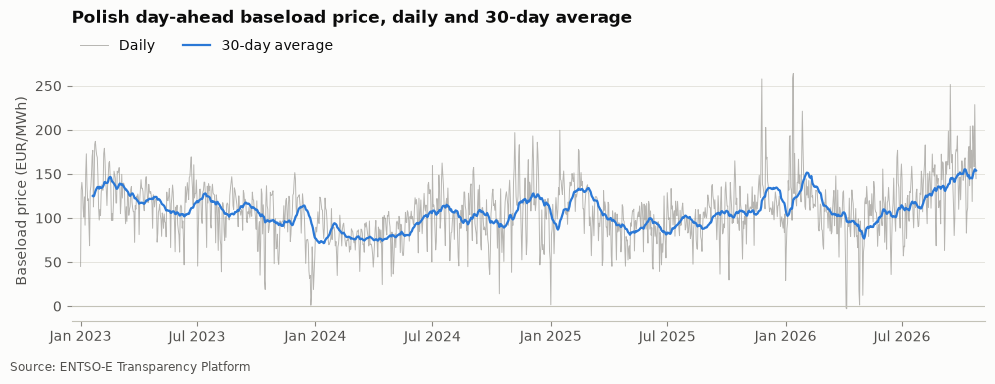

In [3]:
baseload = hourly.groupby('day')['price'].mean()
rolling_average = baseload.rolling(30, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(baseload.index, baseload, color=MUTED, lw=0.7, alpha=0.6, label='Daily')
ax.plot(rolling_average.index, rolling_average, color=BLUE, lw=1.6, label='30-day average')
ax.axhline(0, color=BASELINE, lw=0.8)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_title('Polish day-ahead baseload price, daily and 30-day average', pad=28)
ax.set_ylabel('Baseload price (EUR/MWh)')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)  # a row under the title
ax.margins(x=0.01)
save(fig, 'price_level.png', SOURCE_ENTSOE)

print(f'30-day average: lowest {rolling_average.min():.1f} EUR/MWh on {day_label(rolling_average.idxmin())}, '
      f'highest {rolling_average.max():.1f} on {day_label(rolling_average.idxmax())}')
print('Days above 200 EUR/MWh:', ', '.join(day_label(day) for day in baseload[baseload > 200].index))

monthly = baseload.groupby([baseload.index.month, baseload.index.year]).mean().unstack()
monthly.index = calendar.month_name[1:]
print('Lowest-priced month:', ', '.join(f'{year} {month}' for year, month in monthly.idxmin().items()))
monthly.loc['Whole year'] = baseload.groupby(baseload.index.year).mean()
(monthly.rename_axis(index='Month', columns='Year').style.format('{:.1f}', na_rep='')
 .pipe(captioned, 'Average baseload price by month and year, EUR/MWh'))

- The 30-day mean ranged from 71.4 EUR/MWh on 14 January 2024 to 155.2 on 7 October 2026. Annual baseload averages were 111.7 in 2023, 96.3 in 2024, 104.3 in 2025 and 120.9 in 2026 to 24 October.
- The seasonal pattern varies: the lowest-priced month was December in 2023, March in 2024, June in 2025 and April in 2026. January averaged 93.5 EUR/MWh in 2024 against 143.3 in 2026.
- Nine days had baseload prices above 200 EUR/MWh, all between 25 November 2025 and 22 October 2026. Only 12 and 13 January 2026 were consecutive.

Fuel and carbon costs can shift price levels, but this plot does not identify their contribution. The main models omit these costs; adding carbon in a variant brought no significant gain (README, Variants).

## 2. Intraday profile

Hourly prices over the last 365 delivery days, by hour (Warsaw time) and day. The colour scale is clipped at the 2nd and 98th percentiles; the empty cell in March is the hour skipped at the clock change.

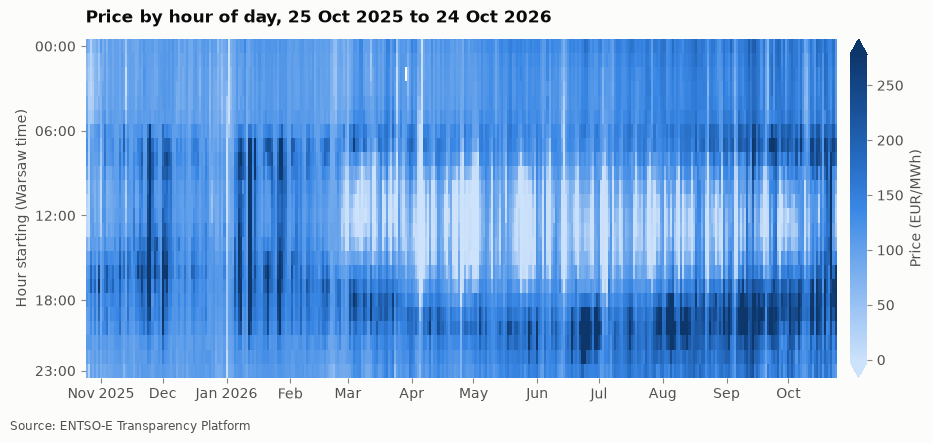

In [4]:
last_year = hourly[hourly['day'] > hourly['day'].max() - pd.Timedelta(days=365)]
hour_of_day = last_year['local'].dt.hour
# One row per hour of the day, one column per delivery day; the October 02:00, which occurs twice, is averaged.
price_grid = last_year.pivot_table(index=hour_of_day, columns='day', values='price')
colour_min, colour_max = last_year['price'].quantile([0.02, 0.98])
colours = LinearSegmentedColormap.from_list('price', BLUE_RAMP)
colours.set_bad(SURFACE)  # the 02:00 skipped when the clocks go forward

fig, ax = plt.subplots(figsize=(10, 4.4))
heatmap = ax.imshow(price_grid.to_numpy(), aspect='auto', cmap=colours, vmin=colour_min, vmax=colour_max,
                    interpolation='nearest')
days = price_grid.columns
month_starts = [position for position, day in enumerate(days) if day.day == 1]
ax.set_xticks(month_starts, [days[p].strftime('%b %Y' if p == month_starts[0] or days[p].month == 1 else '%b')
                             for p in month_starts])
ax.set_yticks([0, 6, 12, 18, 23], ['00:00', '06:00', '12:00', '18:00', '23:00'])
ax.grid(False)
ax.spines['bottom'].set_visible(False)
ax.set_title(f'Price by hour of day, {day_label(days[0], weekday=False)} to {day_label(days[-1], weekday=False)}')
ax.set_ylabel('Hour starting (Warsaw time)')
colour_bar = fig.colorbar(heatmap, ax=ax, extend='both', pad=0.015)  # the pointed ends mark hourly beyond the cut
colour_bar.set_label('Price (EUR/MWh)')
colour_bar.outline.set_visible(False)
save(fig, 'price_by_hour.png', SOURCE_ENTSOE)

month = last_year['day'].dt.to_period('M')
mean_by_hour = last_year.pivot_table(index=month, columns=hour_of_day, values='price')
trough_and_peak = pd.DataFrame({
    ('Days', ''): last_year.groupby(month)['day'].nunique(),
    ('Trough hour', 'starts'): mean_by_hour.idxmin(axis=1).map('{:02d}:00'.format),
    ('Trough hour', 'average price'): mean_by_hour.min(axis=1),
    ('Peak hour', 'starts'): mean_by_hour.idxmax(axis=1).map('{:02d}:00'.format),
    ('Peak hour', 'average price'): mean_by_hour.max(axis=1),
    ('Intraday spread', ''): mean_by_hour.max(axis=1) - mean_by_hour.min(axis=1),
})
trough_and_peak.index = trough_and_peak.index.strftime('%b %Y').rename('Month')
trough_and_peak.style.format(precision=0).pipe(captioned, 
    'Daily trough and peak hour by month, average price in EUR/MWh (Warsaw time)')

- From March to October 2026, monthly average profiles had a midday trough and an evening peak, separated by 150 to 222 EUR/MWh. The trough was at 13:00 from April to September, averaging −14 EUR/MWh in April.
- From November 2025 to February 2026, the trough was at 02:00–04:00 and the peak at 16:00 or 17:00, with spreads of 62 to 97 EUR/MWh.

Lower summer midday prices are consistent with solar output; PSE reported 26.0 GW of installed PV on 1 February 2026 ([PSE](https://www.pse.pl/redysponowanie-nierynkowe)). Thermal ramping, cycling costs and seasonal demand may also contribute. This analysis does not isolate their effects.

## 3. Negative prices

Hours with a negative price, by month and year; from October 2025 an hour counts if the mean of its quarter-hour prices is negative. Negative prices arise when inflexible output (coal units at minimum stable load, heat-led CHP, renewables paid regardless of the price) exceeds demand plus exports. PSE also curtailed 1,376 GWh of renewables in 2025, mostly midday solar ([Gramwzielone.pl](https://www.gramwzielone.pl/?p=20369542)). The last month is incomplete.

Year,2023,2024,2025,2026
Month,,,,
January,0,0,11,9
February,0,0,0,4
March,0,0,44,39
April,0,15,75,87
May,0,31,49,53
June,5,19,72,32
July,0,28,5,40
August,0,39,36,29
September,0,26,13,21


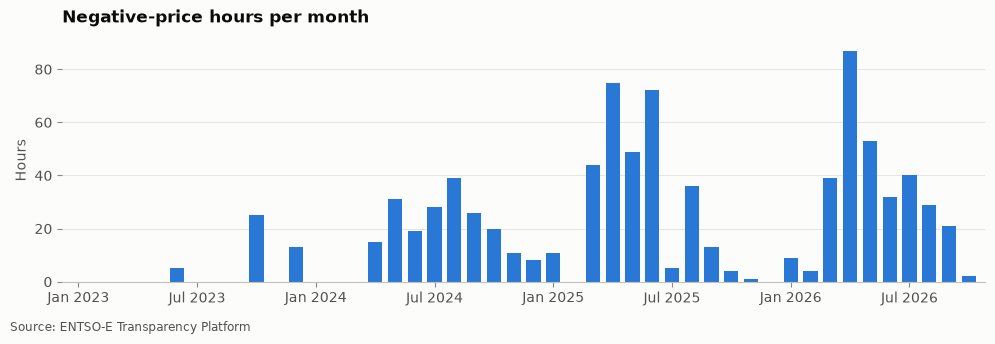

In [5]:
negative = hourly['price'] < 0
negative_by_month = negative.groupby(hourly['day'].dt.to_period('M')).sum()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(negative_by_month)), negative_by_month, width=0.72, color=BLUE)
label_positions = [position for position, month in enumerate(negative_by_month.index) if month.month in (1, 7)]
ax.set_xticks(label_positions, negative_by_month.index[label_positions].strftime('%b %Y'))
ax.set_title('Negative-price hours per month')
ax.set_ylabel('Hours')
ax.margins(x=0.01)
save(fig, 'negative_hours.png', SOURCE_ENTSOE)

negative_hours = negative.groupby([hourly['day'].dt.month, hourly['day'].dt.year]).sum().unstack()
negative_hours.index = calendar.month_name[1:]
negative_hours.loc['Whole year'] = negative_hours.sum()
(negative_hours.rename_axis(index='Month', columns='Year').style.format('{:.0f}', na_rep='')
 .pipe(captioned, 'Negative-price hours by month and year'))

Negative-price hours increased from 43 in 2023 to 316 by 24 October 2026, already exceeding 2025's 310. The next table groups them by season, hour and weekend status.

In [6]:
negative_times = hourly.loc[negative, 'local']
spring_summer = negative_times[negative_times.dt.month.between(4, 8)]
autumn_winter = negative_times[negative_times.dt.month.isin([10, 11, 12, 1, 2])]
print(f'April to August: {len(spring_summer)} negative-price hours, '
      f'{spring_summer.dt.hour.between(10, 15).mean():.0%} of them in the six hours from 10:00 to 16:00')
print(f'October to February: {len(autumn_winter)} negative-price hours, '
      f'{(~autumn_winter.dt.hour.between(6, 21)).mean():.0%} of them in the eight hours from 22:00 to 06:00')
print(f'Weekends: {(negative_times.dt.dayofweek >= 5).mean():.0%} of negative-price hours, '
      f"against {(hourly['local'].dt.dayofweek >= 5).mean():.0%} of all hours")

April to August: 615 negative-price hours, 87% of them in the six hours from 10:00 to 16:00
October to February: 108 negative-price hours, 54% of them in the eight hours from 22:00 to 06:00
Weekends: 61% of negative-price hours, against 29% of all hours


- Of the 615 negative-price hours from April to August, 87% fell between 10:00 and 16:00.
- Of the 108 from October to February, 54% fell between 22:00 and 06:00.
- Weekends accounted for 61% of negative-price hours, against 29% of all hours.

These patterns are consistent with a midday solar surplus in warmer months and wind combined with low demand on winter nights. They do not identify the contribution of either source. Negative prices also rule out a log transform of the price.

## 4. Solar, load and residual-load accounting

The documentation does not establish how these Polish ENTSO-E forecasts treat behind-the-meter photovoltaic (PV) generation. The source requests are:

| Project field | ENTSO-E REST request, excluding the token and time interval | Data item and use |
|---|---|---|
| `load_fcst` | `documentType=A65`, `processType=A01`, `outBiddingZone_Domain=10YPL-AREA-----S` | Article 6(1)(b) day-ahead total-load forecast |
| `solar_fcst` | `documentType=A69`, `processType=A01`, `in_Domain=10YPL-AREA-----S` | Article 14(1)(d) day-ahead wind-and-solar forecast; receives the returned Solar (B16) series |
| `wind_fcst` | the same A69 request | Wind Onshore (B19) plus Wind Offshore (B18) |

The [ENTSO-E API guide](https://transparency.entsoe.eu/content/static_content/download?path=%2FStatic+content%2Fweb+api%2FRestfulAPI_IG.pdf) maps A65/A01 and A69/A01 to those regulation articles. [Regulation 543/2013, Article 2(27)](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX:02013R0543-20200101) defines total load as a balance quantity—generation plus imports, less exports and power used for storage, including losses. It does not define gross end-user consumption. Article 14(1)(d) requires a solar-generation forecast for the bidding zone, but does not say whether it includes low-voltage or prosumer PV, how self-consumption is estimated, or which meters feed the estimate. The 1 MW threshold in Article 14(1)(a) applies to a separate annual installed-capacity item, not to this forecast.

PSE’s [current five-year planning-report description](https://www.pse.pl/dane-systemowe/plany-pracy-kse/plan-koordynacyjny-5-letni/wielkosci-podstawowe/opis) does document a more specific convention for a different product: it forecasts total PV generation and deducts planned PV autogeneration based on the share of low-voltage prosumer PV from planned network demand. The documentation does not link this product to the ENTSO-E A65 and A69 series or establish a consistent accounting method for the 2023–2026 archive.

The next two checks examine the forecast's scale and its association with load. Neither can establish rooftop coverage or a gross-versus-net convention.

In [7]:
# IRENA's end-of-year maximum net solar-capacity series, in GW: 2023–2025 are the completed
# calendar years in the dataset. It is a national capacity reference, not a definition of what A69 forecasts.
# Source: IRENA, Renewable capacity statistics 2026, solar photovoltaic table and capacity notes; its
# Poland observations are marked u (unofficial) by IRENA, so the table is descriptive only.
SOLAR_CAPACITY_GW = pd.Series({2023: 15.917, 2024: 21.721, 2025: 25.421})

solar_gw_by_year = (hourly['solar_fcst'] / MW_PER_GW).groupby(hourly['day'].dt.year)
capacity_check = pd.DataFrame({
    'National solar capacity (GW)': SOLAR_CAPACITY_GW,
    'Forecast highest hour / capacity': solar_gw_by_year.max() / SOLAR_CAPACITY_GW,
    'Forecast 99.5th percentile / capacity': solar_gw_by_year.quantile(0.995) / SOLAR_CAPACITY_GW,
}).reindex(SOLAR_CAPACITY_GW.index).rename_axis('Year')
(capacity_check.style.format({
    'National solar capacity (GW)': '{:.1f}',
    'Forecast highest hour / capacity': '{:.0%}',
    'Forecast 99.5th percentile / capacity': '{:.0%}',
}).pipe(captioned, 'Scale of the ENTSO-E solar forecast against national solar capacity'))

,National solar capacity (GW),Forecast highest hour / capacity,Forecast 99.5th percentile / capacity
Year,,,
2023,15.9,62%,57%
2024,21.7,58%,52%
2025,25.4,55%,46%


The highest solar forecast is 55% to 62% of the selected year-end national capacity; the 99.5th percentile is 46% to 57%. These ratios describe scale, but cannot establish rooftop or prosumer coverage.

IRENA's values are marked unofficial and measure year-end maximum net generating capacity. The A69 series forecasts generation for a delivery interval. Their installation coverage, AC/DC conventions and treatment of self-consumption may differ. PSE's December 2024 plan reports more than 17 GW of net PV capacity at end-2023 across low- and higher-voltage connections ([pp. 13–14](https://www.pse.pl/documents/20182/21595261/PRSP_2025_2034_dokument_glowny_2024_12_20.pdf/55b0f905-3dd9-4e7e-b33a-78694e893928)). National capacity alone provides no defensible ceiling for utility-scale generation.

### Midday load–solar association

The plot uses one observation per summer weekday at 12:00, with a least-squares line for each year. Temperature, cloud cover, seasonality, calendar effects, demand trends, PV growth and forecasting methods can all affect the association. Neither a positive nor a negative slope establishes whether load is gross or net of behind-the-meter PV.

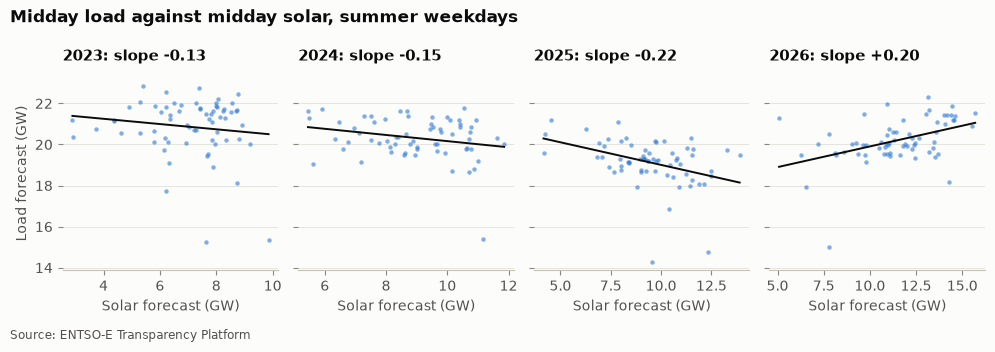

In [8]:
local = hourly['local']
summer_middays = hourly[local.dt.month.isin([6, 7, 8]) & (local.dt.dayofweek < 5) & (local.dt.hour == 12)]
years = sorted(summer_middays['day'].dt.year.unique())

fig, axes = plt.subplots(1, len(years), figsize=(10, 3.4), sharey=True)
for ax, year in zip(axes, years):
    one_summer = summer_middays[summer_middays['day'].dt.year == year]
    solar_gw, load_gw = one_summer['solar_fcst'] / MW_PER_GW, one_summer['load_fcst'] / MW_PER_GW
    slope, intercept = np.polyfit(solar_gw, load_gw, 1)  # least-squares line: load = slope * solar + intercept
    line_ends = np.array([solar_gw.min(), solar_gw.max()])
    ax.scatter(solar_gw, load_gw, s=10, color=BLUE, alpha=0.6, linewidths=0)
    ax.plot(line_ends, slope * line_ends + intercept, color=INK, lw=1.4)
    ax.set_title(f'{year}: slope {slope:+.2f}', fontsize=10.5)
    ax.set_xlabel('Solar forecast (GW)')
axes[0].set_ylabel('Load forecast (GW)')
fig.suptitle('Midday load against midday solar, summer weekdays', x=0.01, ha='left', fontsize=12, fontweight='bold')
save(fig, 'rooftop_check.png', SOURCE_ENTSOE)

The fitted slopes are −0.13, −0.15 and −0.22 GW of load per GW of solar in 2023–2025, and +0.20 in 2026. They describe this summer midday sample without resolving the accounting convention.

The proxy `load_fcst − wind_fcst − solar_fcst` approximates demand left for other generation only if the forecasts have compatible coverage. If load already excludes behind-the-meter PV while solar includes it, subtraction counts that output twice. If load is gross while solar omits it, the proxy leaves that generation unaccounted for. The documentation does not establish which case applies, or whether coverage is consistent across years.

The models use load and renewables as separate features. They do not mechanically subtract rooftop solar twice; any overlap limits feature interpretation, with no demonstrated effect on forecast accuracy.

## 5. Price and residual load

Dots show delivery hours against retrospective target-day residual load. Lines show median prices in 1 GW bands containing at least 30 hours. The price axis displays the pooled 0.5th–99.5th percentiles; medians use all observations. Under the deadline assumption, the target-day renewables input is unavailable to the 11:00 main models.

With compatible accounting, higher residual load implies more demand for other generation or net imports, which can raise prices. The chart is an observed relationship, not an estimated supply curve: fuel and carbon costs, outages, market coupling, weather and bidding also influence prices.


Median target-day residual-load forecast over all hours: 13.8 GW


,2023,2024,2025,2026
Target-day residual-load forecast (GW),,,,
1 to 2,,,-2,-1
2 to 3,,-4,-2,-1
3 to 4,,0,0,0
4 to 5,6,6,0,2
5 to 6,11,7,8,26
6 to 7,16,24,21,59
7 to 8,38,37,54,76
8 to 9,50,60,78,93
9 to 10,66,70,86,108


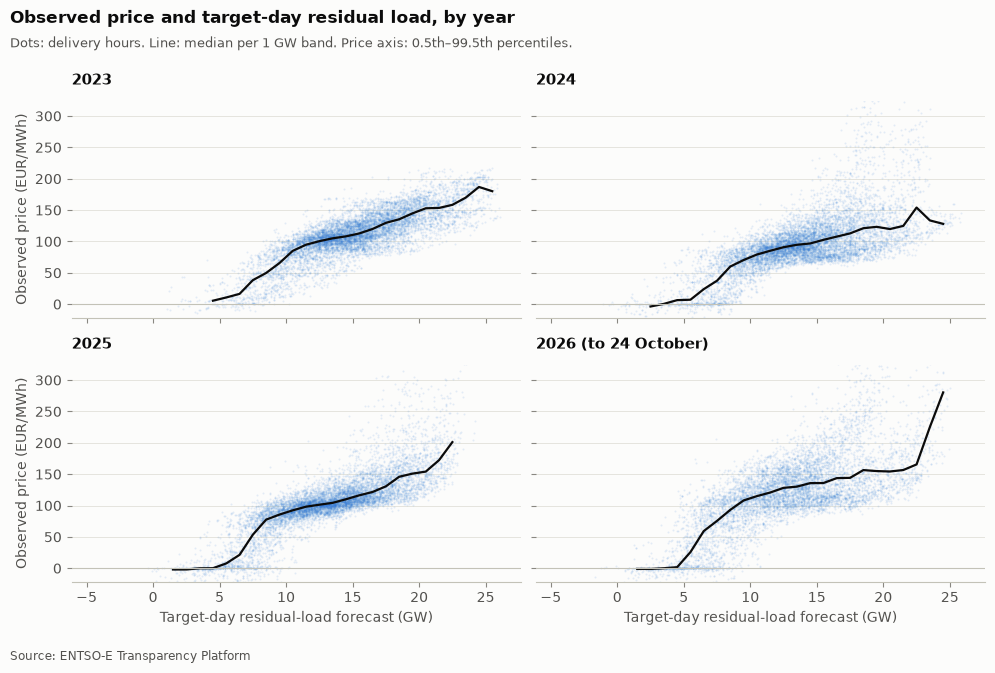

In [9]:
target_residual_gw = hourly['residual_load_fcst'] / MW_PER_GW
band = pd.cut(target_residual_gw, np.arange(np.floor(target_residual_gw.min()), np.ceil(target_residual_gw.max()) + 1))  # 1 GW bands
years = sorted(hourly['day'].dt.year.unique())
last_day = hourly['day'].max()

rows = (len(years) + 1) // 2  # two panels per row
fig, axes = plt.subplots(rows, 2, figsize=(10, 3.3 * rows), sharex=True, sharey=True, squeeze=False)
median_by_band = {}
for ax, year in zip(axes.flat, years):
    in_year = hourly['day'].dt.year == year
    # rasterized stores the thousands of dots as one image, which keeps the file small.
    ax.scatter(target_residual_gw[in_year], hourly.loc[in_year, 'price'], s=2, color=BLUE, alpha=0.12, linewidths=0,
               rasterized=True)
    bands = hourly[in_year].groupby(band[in_year], observed=True)['price'].agg(['median', 'size'])
    median_by_band[year] = bands.loc[bands['size'] >= 30, 'median']
    ax.plot([b.mid for b in median_by_band[year].index], median_by_band[year], color=INK, lw=1.6)
    ax.axhline(0, color=BASELINE, lw=0.8)
    ax.set_title(f'{year} (to {last_day.day} {last_day:%B})' if year == years[-1] else str(year), fontsize=10.5)
for ax in axes.flat[len(years):]:
    ax.set_visible(False)  # an odd number of years leaves one panel empty
for ax in axes[-1]:
    ax.set_xlabel('Target-day residual-load forecast (GW)')
for ax in axes[:, 0]:
    ax.set_ylabel('Observed price (EUR/MWh)')
axes[0, 0].set_ylim(*hourly['price'].quantile([0.005, 0.995]))
fig.suptitle('Observed price and target-day residual load, by year', x=0.01, y=0.995, ha='left', va='top', fontsize=12,
             fontweight='bold')
fig.text(0.01, 0.955, 'Dots: delivery hours. Line: median per 1 GW band. Price axis: 0.5th–99.5th percentiles.',
         ha='left', va='top', color=INK_2, fontsize=9.5)
save(fig, 'merit_order.png', SOURCE_ENTSOE, rect=(0, 0.04, 1, 0.97))

print(f'Median target-day residual-load forecast over all hours: {target_residual_gw.median():.1f} GW')
median_table = pd.DataFrame(median_by_band).sort_index()
median_table.index = [f'{b.left:g} to {b.right:g}' for b in median_table.index]
(median_table.rename_axis('Target-day residual-load forecast (GW)').style.format(whole, na_rep='')
 .pipe(captioned, 'Conditional median observed price per 1 GW band of target-day residual-load forecast, by year (EUR/MWh; bands with at least 30 hours)'))


- Below 5 GW of target-day residual load the conditional median observed price is −4 to 6 EUR/MWh in every year: the two forecast quantities were close, although their accounting compatibility is unverified.
- The observed price–residual-load relationship is steep from 5 to 10 GW and flatter from 10 to 20 GW. In 2026 the median rose from 26 EUR/MWh at 5 to 6 GW to 108 at 9 to 10 GW and 155 at 19 to 20 GW; the other years share the shape at a lower level.
- In 2026 the high-residual-load relationship was steeper: 166 EUR/MWh at 22 to 23 GW and 280 at 24 to 25 GW, against 158 and 187 in 2023.
- The relationship shifts between years: at 13 to 14 GW, the band holding the median target-day residual load of 13.8 GW, the median price was 105 EUR/MWh in 2023, 95 in 2024, 104 in 2025 and 130 in 2026. Lagged prices are the main models' route to such level shifts.


## 6. Rank correlation with price

The table compares target-day load, retrospective target-day residual load and the operational proxy, which uses the preceding day's renewables forecast. All three correlations use the same delivery hours within each year.


In [10]:
correlation_columns = ['price', 'load_fcst', 'residual_load_fcst', 'residual_load_proxy']
correlation_sample = hourly[['day', *correlation_columns]].dropna()
correlation_rows = []
for year, values in correlation_sample.groupby(correlation_sample['day'].dt.year):
    correlations = values[correlation_columns].corr(method='spearman').loc['price']
    correlation_rows.append({
        'Year': year,
        'Hours': len(values),
        'Load forecast': correlations['load_fcst'],
        'Target-day residual load': correlations['residual_load_fcst'],
        'Operational proxy': correlations['residual_load_proxy'],
    })
spearman = pd.DataFrame(correlation_rows).set_index('Year')
(spearman.style.format({'Hours': '{:,.0f}', 'Load forecast': '{:.2f}', 'Target-day residual load': '{:.2f}',
                        'Operational proxy': '{:.2f}'})
 .pipe(captioned, "Spearman's rank correlation with observed price, by year. Each row uses a common sample for all three measures; the operational proxy uses the preceding delivery day's renewables forecast."))


,Hours,Load forecast,Target-day residual load,Operational proxy
Year,,,,
2023,"8,736",0.53,0.79,0.67
2024,"8,784",0.32,0.69,0.56
2025,"8,760",0.48,0.86,0.73
2026,"7,127",0.18,0.70,0.62


- Target-day residual load has a stronger rank correlation with price than load alone in every year: 0.69 to 0.86, against 0.18 to 0.53.
- Using the preceding delivery day's renewables forecast lowers the correlation to 0.56–0.73, a reduction of 0.09 in 2026 and 0.13 in 2024 and 2025. It remains stronger than load alone.

These correlations describe the input–price relationship. They do not estimate the causal value of forecast availability or the MAE improvement a model would achieve. The models also use other inputs and are evaluated out of sample.


## Implications for the models

- The level drifts, so the models train on the latest 365 days, retrained daily, with lagged prices as inputs.
- The solar effect is hour-specific, one reason the linear model fits a separate regression for each hour; the trees take the hour as an input.
- The observed price–residual-load relationship motivates load and renewables as inputs. The main models receive them separately and use the preceding delivery day's renewables forecast, not the retrospective target-day residual load.
- Single hours reach −469.2 and 663.2 EUR/MWh, so accuracy is measured by MAE, which extreme hours dominate less than squared error.

## Sources

- [ENTSO-E Transparency Platform REST API guide](https://transparency.entsoe.eu/content/static_content/download?path=%2FStatic+content%2Fweb+api%2FRestfulAPI_IG.pdf): version 0.3 draft, revision history through 15 July 2016, pp. 8 and 13; the A65/A01 load and A69/A01 wind-and-solar request mappings used by this project.
- [Commission Regulation (EU) No 543/2013, consolidated text](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX:02013R0543-20200101): 14 June 2013; consolidated text of 1 January 2020. Article 2(27), Article 6 and Article 14 define the legal data items and reporting obligations.
- [PSE, description of five-year planning-report quantities](https://www.pse.pl/dane-systemowe/plany-pracy-kse/plan-koordynacyjny-5-letni/wielkosci-podstawowe/opis): current web description, accessed 15 November 2026, of planned network demand, PV autogeneration and total PV forecast. It is a separate PSE product, not evidence that the ENTSO-E series has the same construction.
- [PSE, Plan rozwoju sieci przesyłowej 2025–2034](https://www.pse.pl/documents/20182/21595261/PRSP_2025_2034_dokument_glowny_2024_12_20.pdf/55b0f905-3dd9-4e7e-b33a-78694e893928), December 2024, pp. 13–14: PV capacity by connection level at end-2023 and the importance of prosumer capacity.
- [IRENA, Renewable capacity statistics 2026](https://www.irena.org/-/media/Files/IRENA/Agency/Publication/2026/Mar/IRENA_DAT_RE_Capacity_Statistics_2026.pdf): March 2026, pp. 2 and 25; the annual national solar-capacity reference used in Section 4. Capacity is maximum net generating capacity at calendar year end. Its Poland PV observations are marked `u` (unofficial) by IRENA, so the comparison is descriptive only.
- [ENTSO-E Transparency Platform](https://transparency.entsoe.eu/): day-ahead prices and the day-ahead forecasts of load, wind and solar.
- [EPEX SPOT, 15-minute products in market coupling](https://epexspot.com/de/node/4164): gate closure time and the 60-minute index as the average of 15-minute prices.
- [HUPX, 15-minute MTU implemented in SDAC](https://hupx.hu/2025/10/01/15-minute-mtu-implemented-sdac): first 15-minute delivery day, 1 October 2025.
- [Gramwzielone.pl, renewable curtailment in Poland](https://www.gramwzielone.pl/?p=20369542): curtailment volumes by year.
